<a href="https://colab.research.google.com/github/09StevenG/2022-ii-tutorial-git-repo-ejemplo/blob/main/semana_07_interpolacion_21_oct_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Paso 0 librerias a utilizar
import numpy as np                 # mallas y cálculos
import pandas as pd                # tablas para leer las estaciones
import geopandas as gpd            # datos geoespaciales
import matplotlib.pyplot as plt    # gráficas
import rasterio                    # exportar GeoTIFF
from rasterio.transform import from_origin
from rasterio.mask import mask
import shapely                     # geometría: distancias, puntos dentro de polígonos
from shapely import contains_xy
from shapely.geometry import LineString

In [ ]:
# Paso 1 los datos
url = "https://raw.githubusercontent.com/navilaufm/geodata/main/STAN_coordenadas_valor.csv"
datos = pd.read_csv(url)
datos = datos.rename(columns={"estnombre": "nombre", "estlatitude": "latitud", "estlongitude": "longitud", "valor": "mm"})
datos

,nombre,latitud,longitud,mm
0,21 de Octubre,14.18330,-87.17445,63.7
1,Acajutla Puerto Nuevo,13.56780,-89.84720,595.3
2,Aeropuerto De Ilopango,13.68580,-89.11860,428.7
3,Agua Caliente,14.58000,-87.15250,59.6
4,"Alameda Icta, Chimaltenango",14.63380,-90.80330,149.7
...,...,...,...,...
118,Tonosi,7.40000,-80.45750,25.4
119,Towerhill,18.03333,-88.56667,114.1
120,Trujillo,15.92579,-85.93867,35.4
121,Valle Rico,7.61670,-80.35580,40.0


In [ ]:
datos.describe()

,latitud,longitud,mm
count,123.000000,123.000000,123.000000
mean,13.643191,-87.125300,116.720325
std,2.930454,3.349206,138.944985
min,7.400000,-91.810000,0.900000
25%,11.996500,-89.423550,33.300000
50%,14.520000,-88.241900,64.500000
75%,15.483950,-85.857200,130.350000
max,18.283330,-79.100000,616.400000


In [ ]:
# convertir la tabla en puntos geográficos
estaciones = gpd.GeoDataFrame(datos, geometry=gpd.points_from_xy(datos.longitud, datos.latitud), crs="EPSG:4326")
estaciones

,nombre,latitud,longitud,mm,geometry
0,21 de Octubre,14.18330,-87.17445,63.7,POINT (-87.17445 14.1833)
1,Acajutla Puerto Nuevo,13.56780,-89.84720,595.3,POINT (-89.8472 13.5678)
2,Aeropuerto De Ilopango,13.68580,-89.11860,428.7,POINT (-89.1186 13.6858)
3,Agua Caliente,14.58000,-87.15250,59.6,POINT (-87.1525 14.58)
4,"Alameda Icta, Chimaltenango",14.63380,-90.80330,149.7,POINT (-90.8033 14.6338)
...,...,...,...,...,...
118,Tonosi,7.40000,-80.45750,25.4,POINT (-80.4575 7.4)
119,Towerhill,18.03333,-88.56667,114.1,POINT (-88.56667 18.03333)
120,Trujillo,15.92579,-85.93867,35.4,POINT (-85.93867 15.92579)
121,Valle Rico,7.61670,-80.35580,40.0,POINT (-80.3558 7.6167)


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

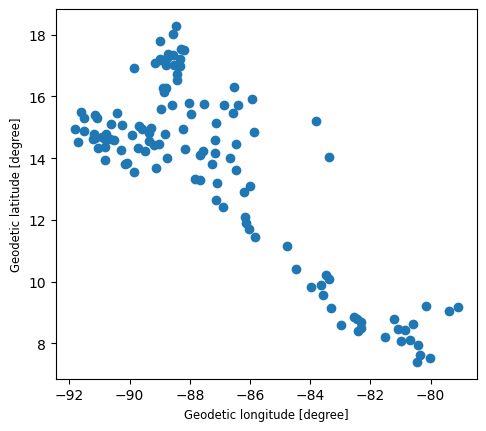

In [ ]:
estaciones.plot()

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

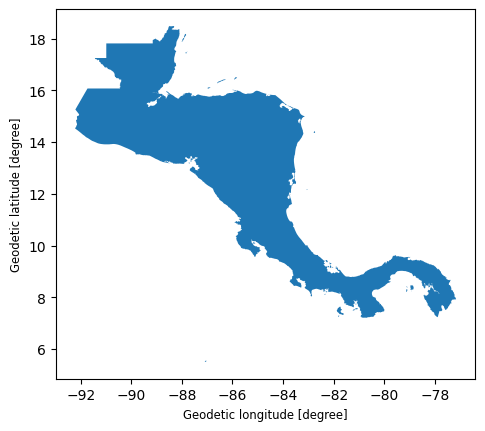

In [ ]:
frontera = gpd.read_file("https://raw.githubusercontent.com/navilaufm/geodata/main/CAM.geojson")
frontera.plot()


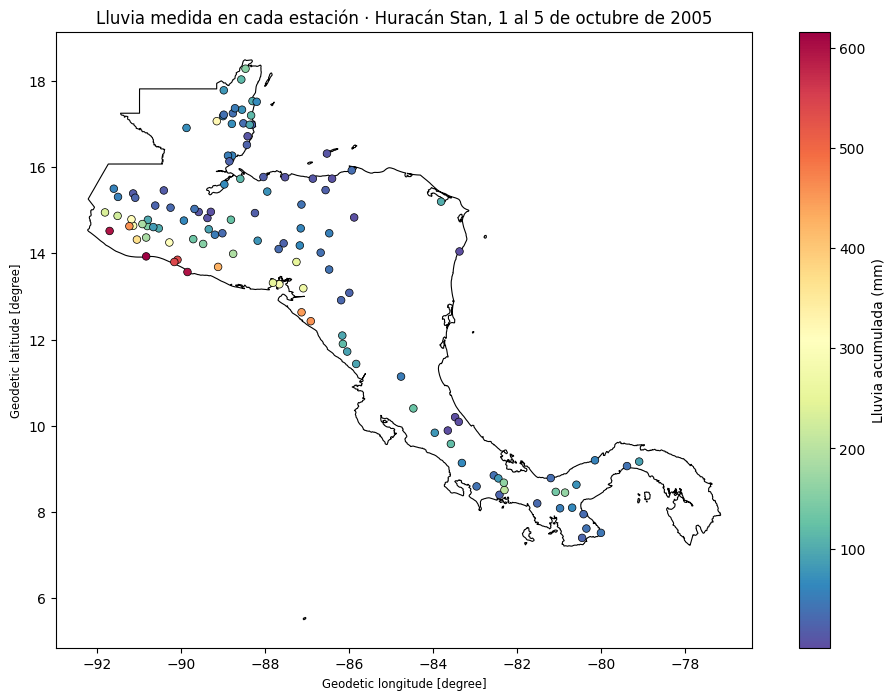

In [ ]:
fig, ax = plt.subplots(figsize=(12, 8))
frontera.plot(ax=ax, color="none", edgecolor="black", linewidth=0.8)
estaciones.plot(ax=ax, column="mm", cmap="Spectral_r", legend=True, markersize=30, edgecolor="black", linewidth=0.5,
                legend_kwds={"label": "Lluvia acumulada (mm)"})
ax.set_title("Lluvia medida en cada estación · Huracán Stan, 1 al 5 de octubre de 2005")
plt.show()

In [ ]:
#paso 2 la malla, el conjunto de puntos donde vamos a estimar.
RES = 0.05 #en grados (porque los rasters funcionan en grados)

# extensión de la frontera, redondeada a múltiplos de 0.05
xmin, ymin, xmax, ymax = frontera.total_bounds  #basado en la geometria.
xmin, ymin = np.floor(xmin / RES) * RES, np.floor(ymin / RES) * RES
xmax, ymax = np.ceil(xmax / RES) * RES, np.ceil(ymax / RES) * RES

# centros de las celdas: oeste → este y norte → sur
xs = np.arange(xmin, xmax, RES) + RES / 2
ys = np.arange(ymax, ymin, -RES) - RES / 2
xi, yi = np.meshgrid(xs, ys)
ny, nx = xi.shape

# solo interesan las celdas sobre tierra
tierra = contains_xy(frontera.union_all(), xi, yi) #filtrando para que nuestro algoritmo SOLO corra dentro de la frontera. (tierra)

# los centros de las celdas como puntos geográficos, igual que las estaciones
puntos_malla = gpd.GeoSeries(gpd.points_from_xy(xi.ravel(), yi.ravel()), crs="EPSG:4326")

print(f"malla: {ny} filas × {nx} columnas = {nx * ny} celdas, {tierra.sum()} sobre tierra")

malla: 260 filas × 302 columnas = 78520 celdas, 17201 sobre tierra


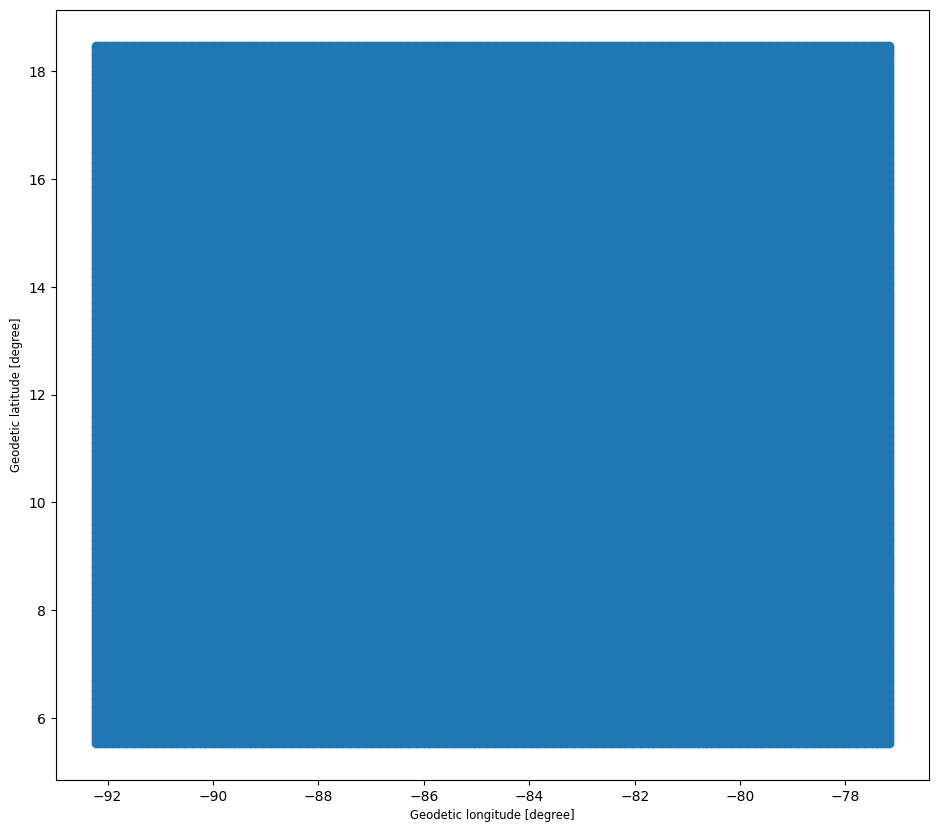

In [ ]:
#mapear puntos_malla mas grande
fig, ax = plt.subplots(figsize=(20, 10))
frontera.plot(ax=ax, color="none", edgecolor="black", linewidth=0.6)
ax.scatter(puntos_malla.x, puntos_malla.y)

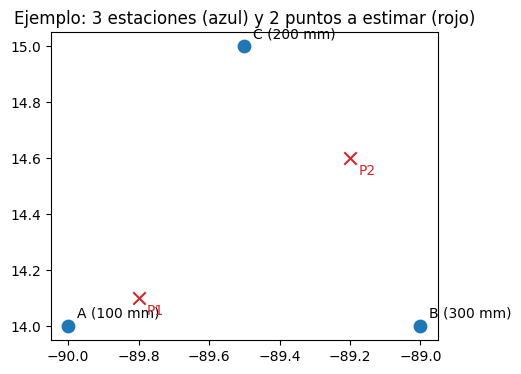

In [ ]:
#como verlo a detalle
ej_est = pd.DataFrame({"estacion": ["A", "B", "C"],
                       "x": [-90.0, -89.0, -89.5],
                       "y": [14.0, 14.0, 15.0],
                       "mm": [100, 300, 200]})
ej_pts = pd.DataFrame({"punto": ["P1", "P2"],
                       "x": [-89.8, -89.2],
                       "y": [14.1, 14.6]})

# como puntos geográficos, igual que en la semana 3
ej_est = gpd.GeoDataFrame(ej_est, geometry=gpd.points_from_xy(ej_est.x, ej_est.y), crs="EPSG:4326")
ej_pts = gpd.GeoDataFrame(ej_pts, geometry=gpd.points_from_xy(ej_pts.x, ej_pts.y), crs="EPSG:4326")

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(ej_est.x, ej_est.y, s=80, c="tab:blue")
ax.scatter(ej_pts.x, ej_pts.y, s=80, c="tab:red", marker="x")
for _, r in ej_est.iterrows():
    ax.annotate(f"{r.estacion} ({r.mm} mm)", (r.x, r.y), xytext=(6, 6), textcoords="offset points")
for _, r in ej_pts.iterrows():
    ax.annotate(r.punto, (r.x, r.y), xytext=(6, -12), textcoords="offset points", color="tab:red")
ax.set_title("Ejemplo: 3 estaciones (azul) y 2 puntos a estimar (rojo)")
plt.show()

In [ ]:
#paso 3, las funciones son los algoritmos, IDW, y Vecino mas cercano

#funcion de distancia
def distance_matrix(estaciones, puntos):
    columna = np.asarray(estaciones)[:, None]     # estaciones en columna
    fila = np.asarray(puntos)[None, :]            # puntos en fila
    return shapely.distance(columna, fila)        # distancia de cada estación a cada punto

d = distance_matrix(ej_est.geometry, ej_pts.geometry)
pd.DataFrame(d.round(3), index=ej_est.estacion, columns=ej_pts.punto)

punto,P1,P2
estacion,,
A,0.224,1.000
B,0.806,0.632
C,0.949,0.500


In [ ]:
#función del vecino cercano
def vecino_cercano(estaciones, z, puntos):
    dist = distance_matrix(estaciones, puntos)
    mas_cercana = dist.argmin(axis=0)   # en cada columna, la fila con menor distancia
    return z[mas_cercana]               # el valor de esa estación

print("estación más cercana a cada punto:", list(ej_est.estacion[d.argmin(axis=0)]))
print("valor estimado:", vecino_cercano(ej_est.geometry, ej_est.mm.values, ej_pts.geometry))

estación más cercana a cada punto: ['A', 'C']
valor estimado: [100 200]


In [ ]:
#funcion IDW
def simple_idw(estaciones, z, puntos, potencia=2):
    dist = distance_matrix(estaciones, puntos)
    pesos = dist ** (-potencia)         # 1. peso crudo: 1 / distancia^potencia
    pesos /= pesos.sum(axis=0)          # 2. normalizar: los pesos de cada punto suman 1
    return np.dot(pesos.T, z)           # 3. suma de peso × valor de cada estación

print("valor estimado:", simple_idw(ej_est.geometry, ej_est.mm.values, ej_pts.geometry, potencia=2).round(1))

valor estimado: [118.5 220. ]


In [ ]:
# las estaciones como puntos y su lluvia medida - esta función mapa sirve para mapear la malla calculada de cada método
geom = estaciones.geometry
z = estaciones.mm.values
x, y = estaciones.longitud.values, estaciones.latitud.values     # solo para dibujar

def mapa(matriz, titulo, ax=None, vmax=500):
    # dibuja una malla sobre tierra con las estaciones y la frontera
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 8))
    im = ax.imshow(np.where(tierra, matriz, np.nan), extent=(xmin, xmax, ymin, ymax), cmap="Spectral_r", vmin=0, vmax=vmax)
    frontera.plot(ax=ax, color="none", edgecolor="black", linewidth=0.6)
    ax.scatter(x, y, color="black", s=4)
    ax.set_title(titulo)
    plt.colorbar(im, ax=ax, label="Lluvia acumulada (mm)", shrink=0.7)
    return ax

<Axes: title={'center': 'Vecino mas cercano - Nearest Neighbor - Huracán Stan'}, xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

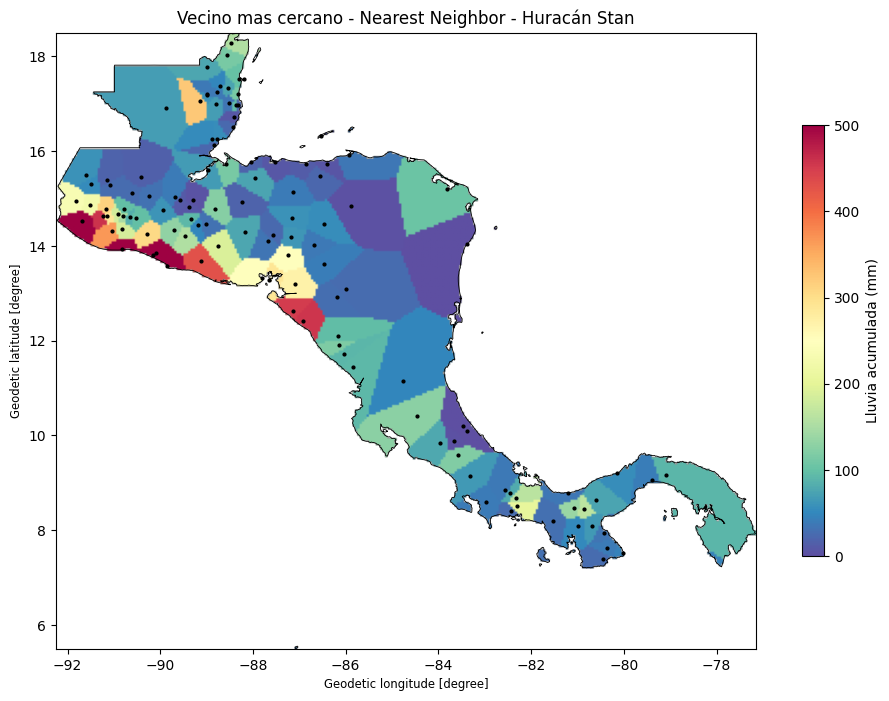

In [ ]:
#ver para toda la malla usando los polígonos de Thiessen (Vecino mas cercano - Nearest Neighbor)
grilla_vecino = vecino_cercano(geom, z, puntos_malla).reshape(ny, nx)
# usamos la función de mapa para ver la grilla
mapa(grilla_vecino, "Vecino mas cercano - Nearest Neighbor - Huracán Stan")

<Axes: title={'center': 'Interpolación IDW - Huracán Stan'}, xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

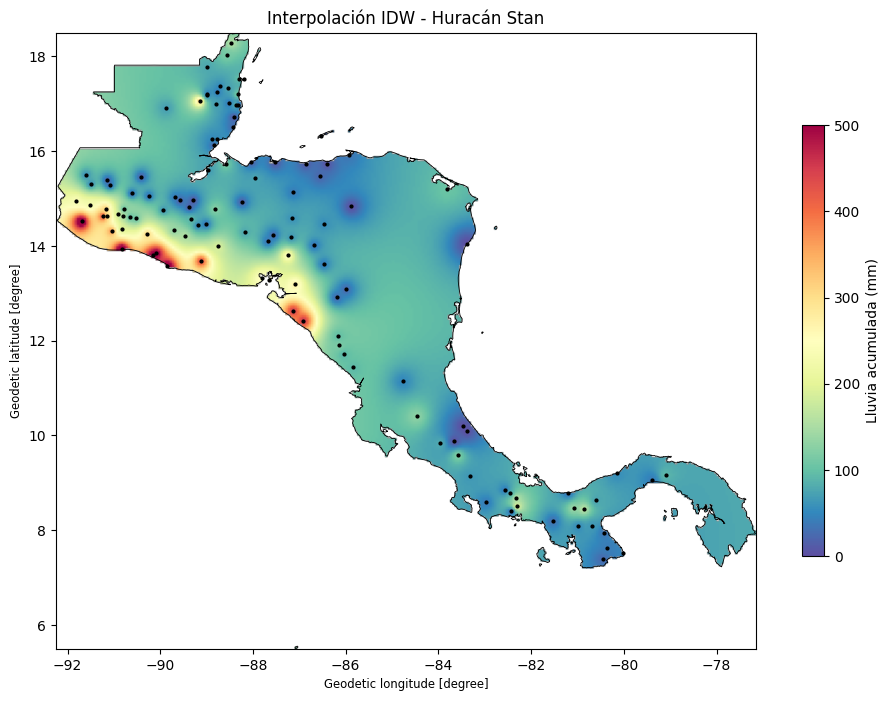

In [ ]:
#ver para toda la malla usando los polígonos de Thiessen (Vecino mas cercano - Nearest Neighbor)
grilla_idw = simple_idw(geom, z, puntos_malla,potencia=2).reshape(ny, nx)
# usamos la función de mapa para ver la grilla
mapa(grilla_idw, "Interpolación IDW - Huracán Stan")

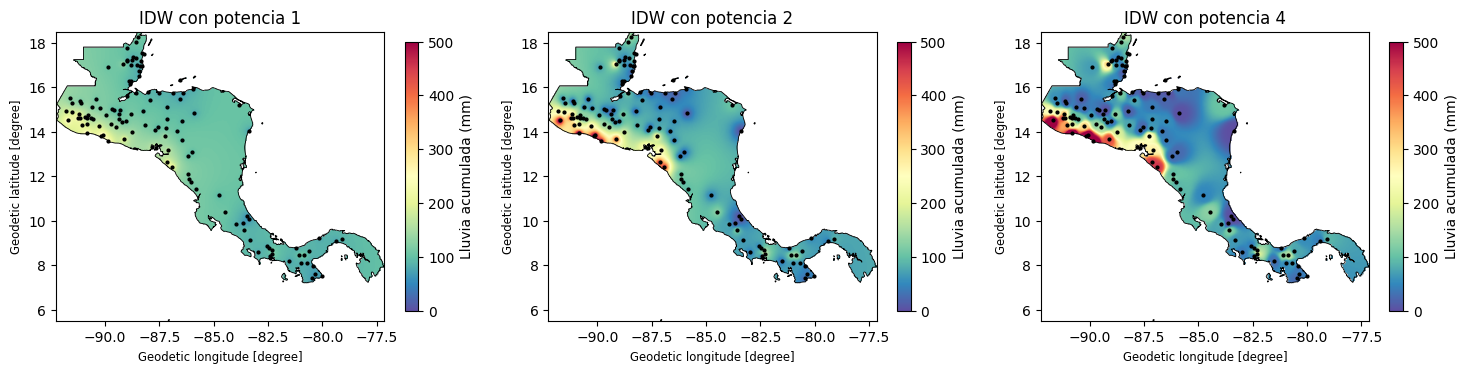

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
for ax, p in zip(axs, [1, 2, 4]):
    g = simple_idw(geom, z, puntos_malla, potencia=p).reshape(ny, nx)
    mapa(g, f"IDW con potencia {p}", ax=ax)
plt.show()

In [ ]:
#validación cruzada, nos permite determinar el mejor exponente (donde el error es menor)
#funcion para validar que exponente usar
def validacion_cruzada(potencia, puntos=geom):
    errores = []
    for i in range(len(z)):
        otras = np.arange(len(z)) != i                     # todas menos la estación i
        estimado = simple_idw(puntos[otras], z[otras], puntos.iloc[[i]], potencia)[0]
        errores.append(estimado - z[i])
    return np.sqrt(np.mean(np.square(errores)))            # error típico (RMSE)



In [ ]:
#prueba de la función de validación cruzada con varias potencias
potencias = [1, 1.5, 2, 2.5, 3,3.2, 3.5, 3.7, 4, 4.5, 4.8, 5, 6]
tabla_potencias = pd.DataFrame({"potencia": potencias,
                                "error_tipico_mm": [round(validacion_cruzada(p), 1) for p in potencias]})

P_OPTIMA = float(tabla_potencias.loc[tabla_potencias.error_tipico_mm.idxmin(), "potencia"])
print(f"potencia con menor error: {P_OPTIMA:g}")
tabla_potencias

potencia con menor error: 4


,potencia,error_tipico_mm
0,1.0,117.4
1,1.5,101.2
2,2.0,87.9
3,2.5,79.8
4,3.0,75.7
5,3.2,74.8
6,3.5,74.0
7,3.7,73.8
8,4.0,73.6
9,4.5,73.9


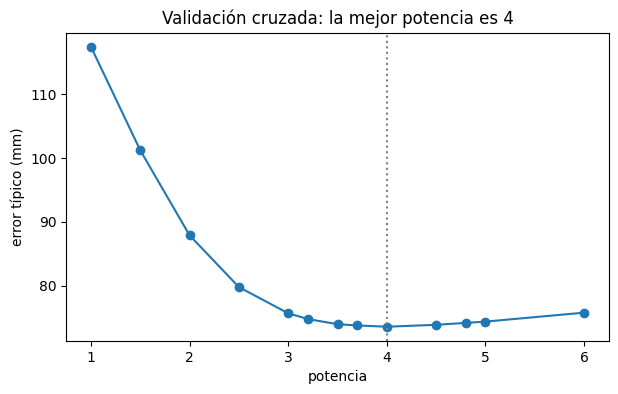

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(tabla_potencias.potencia, tabla_potencias.error_tipico_mm, "o-")
plt.axvline(P_OPTIMA, color="gray", linestyle=":")
plt.xlabel("potencia")
plt.ylabel("error típico (mm)")
plt.title(f"Validación cruzada: la mejor potencia es {P_OPTIMA:g}")
plt.show()

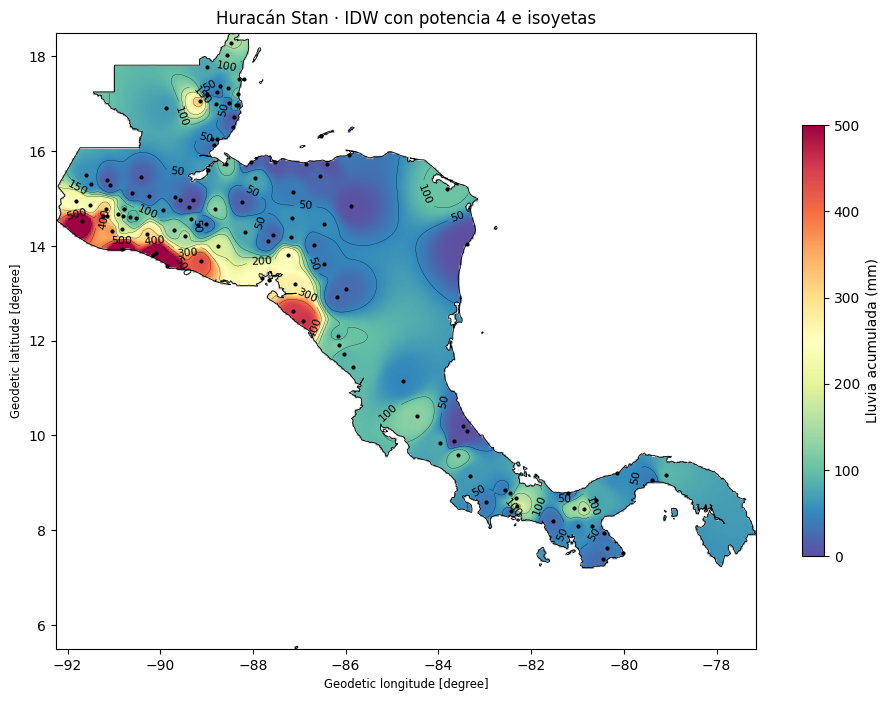

In [ ]:
grilla_final = simple_idw(geom, z, puntos_malla, potencia=P_OPTIMA).reshape(ny, nx)

ax = mapa(grilla_final, f"Huracán Stan · IDW con potencia {P_OPTIMA:g} e isoyetas")
isoyetas = ax.contour(xi, yi, np.where(tierra, grilla_final, np.nan),
                      levels=[50, 100, 150, 200, 300, 400, 500], colors="black", linewidths=0.2)
ax.clabel(isoyetas, fmt="%d", fontsize=8)
plt.show()

In [ ]:
#voy a exportar varios rasters (1 por cada método), para esto creo una funcion de guardar geotiff
def guardar_tif(nombre, matriz):
    datos = np.where(tierra, matriz, -9999).astype("float32")      # fuera de tierra: sin dato
    with rasterio.open(nombre, "w", driver="GTiff", height=ny, width=nx, count=1, dtype="float32",
                       crs="EPSG:4326", transform=from_origin(xmin, ymax, RES, RES), nodata=-9999) as dst:
        dst.write(datos, 1)
    print("guardado:", nombre)

In [ ]:
#genero los 3 rasters
guardar_tif("stan_vecino.tif", grilla_vecino)
guardar_tif("stan_idw_p2.tif", grilla_idw)
guardar_tif("stan_idw_optima.tif", grilla_final)

guardado: stan_vecino.tif
guardado: stan_idw_p2.tif
guardado: stan_idw_optima.tif


In [ ]:
import rasterio

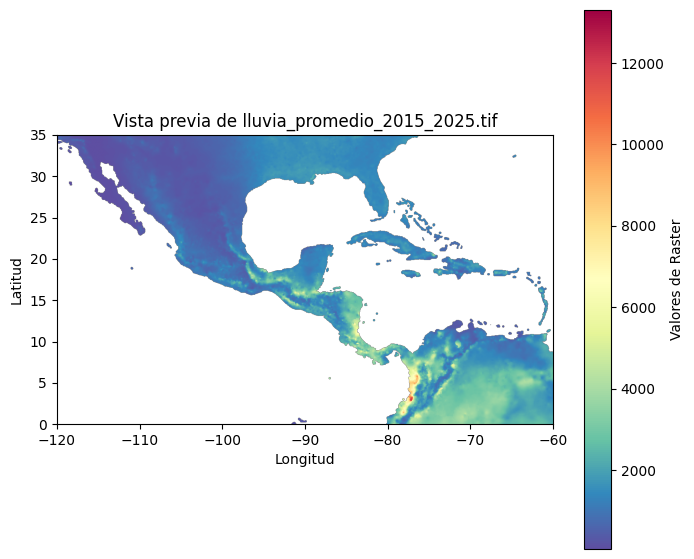

In [ ]:
#mostrar raster de climatologia
import rasterio
import matplotlib.pyplot as plt

url_raster = "https://github.com/navilaufm/geodata/raw/refs/heads/main/catie/lluvia_promedio_2015_2025.tif"

with rasterio.open(url_raster) as src:
    raster_data = src.read(1, masked=True)
    spatial_extent = (
        src.bounds.left,
        src.bounds.right,
        src.bounds.bottom,
        src.bounds.top
    )

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(raster_data, extent=spatial_extent, cmap="Spectral_r")
plt.colorbar(im, ax=ax, label="Valores de Raster")
ax.set_title("Vista previa de lluvia_promedio_2015_2025.tif")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
plt.show()